In [1]:
print("Name:Waheed Ullah")
print("Roll No:23p-3079")

Name:Waheed Ullah
Roll No:23p-3079


**Task1**

In [2]:
import math
import random

In [3]:
data = [
 [5.1, 3.5, 1.4, 0.2],
 [4.9, 3.0, 1.4, 0.2],
 [5.0, 3.4, 1.5, 0.2],
 [4.8, 3.1, 1.6, 0.2],
 [7.0, 3.2, 4.7, 1.4],
 [6.4, 3.2, 4.5, 1.5],
 [5.5, 2.3, 4.0, 1.3],
 [6.5, 2.8, 4.6, 1.5],
 [6.3, 3.3, 6.0, 2.5],
 [7.1, 3.0, 5.9, 2.1],
 [6.5, 3.0, 5.8, 1.8],
 [7.6, 3.0, 6.6, 2.1]
]

**Function1**

In [4]:
def euclidean_distance(point1, point2):
    return math.sqrt(sum((point1[i] - point2[i])**2 for i in range(len(point1))))

**Function2**

In [5]:
def assign_clusters(data, centroids):
    assignments = []
    for point in data:
        distances = []
        for centroid in centroids:
            dist = euclidean_distance(point, centroid)
            distances.append(dist)
        assignments.append(distances.index(min(distances)))
    return assignments

**Function3**

In [6]:
def update_centroids(data, assignments, k):
    new_centroids = []

    for cluster_id in range(k):
        cluster_points = [data[i] for i in range(len(data)) if assignments[i] == cluster_id]

        centroid = []
        for f in range(len(data[0])):
            mean = sum(point[f] for point in cluster_points) / len(cluster_points)
            centroid.append(mean)

        new_centroids.append(centroid)

    return new_centroids

**Function4**

In [7]:
def kmeans(data, k, max_iter=100):
    random.seed(42)
    centroids = [data[i][:] for i in random.sample(range(len(data)), k)]

    for _ in range(max_iter):
        assignments = assign_clusters(data, centroids)
        new_centroids = update_centroids(data, assignments, k)

        
        if all(abs(centroids[i][j] - new_centroids[i][j]) < 0.0001
               for i in range(k)
               for j in range(len(data[0]))):
            break

        centroids = new_centroids

    return assignments, centroids



In [8]:
K = 3
assignments, centroids = kmeans(data, K)

print("Cluster Assignments:", assignments)
print("Centroids:", centroids)

for i, point in enumerate(data):
    print(point, "-> Cluster", assignments[i])

Cluster Assignments: [2, 1, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0]
Centroids: [[6.6125, 2.975, 5.2625, 1.775], [4.85, 3.05, 1.5, 0.2], [5.05, 3.45, 1.45, 0.2]]
[5.1, 3.5, 1.4, 0.2] -> Cluster 2
[4.9, 3.0, 1.4, 0.2] -> Cluster 1
[5.0, 3.4, 1.5, 0.2] -> Cluster 2
[4.8, 3.1, 1.6, 0.2] -> Cluster 1
[7.0, 3.2, 4.7, 1.4] -> Cluster 0
[6.4, 3.2, 4.5, 1.5] -> Cluster 0
[5.5, 2.3, 4.0, 1.3] -> Cluster 0
[6.5, 2.8, 4.6, 1.5] -> Cluster 0
[6.3, 3.3, 6.0, 2.5] -> Cluster 0
[7.1, 3.0, 5.9, 2.1] -> Cluster 0
[6.5, 3.0, 5.8, 1.8] -> Cluster 0
[7.6, 3.0, 6.6, 2.1] -> Cluster 0


**Which K is best?**

K = 3 is best

**If K = 2**

Two clusters merge → loss of detail

**if K=4**

Over-segmentation (unnecessary splitting)

**Task2**

In [23]:
print("Name:Waheed Ullah")
print("Roll No:23p-3079")

Name:Waheed Ullah
Roll No:23p-3079


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


In [11]:
df = pd.read_csv('Mall_Customers.csv')

In [12]:
df = df.select_dtypes(exclude=['object'])
df = df.fillna(df.mean())

In [13]:
scaler = StandardScaler()
X = scaler.fit_transform(df)


In [14]:
k_values = range(1, 11)
inertias = []

In [15]:
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    inertias.append(kmeans.inertia_)

C:\Users\STUDENT\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\STUDENT\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 282, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")
C:\Users\STUDENT\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\STUDENT\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with

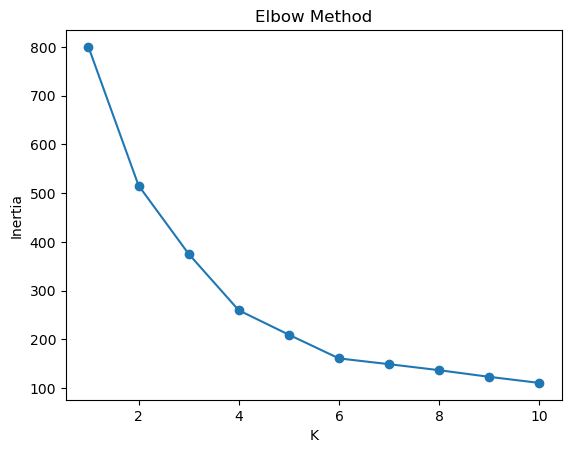

In [16]:
plt.plot(k_values, inertias, marker='o')
plt.title('Elbow Method')
plt.xlabel('K')
plt.ylabel('Inertia')
plt.show()

**1. Elbow point?**

Usually appears around K = 4 or 5
That is optimal clusters

**2. Why scaling?**

Because:

Features have different ranges
Without scaling → large values dominate distance

**3. What if K = 1?**

Only ONE cluster
Centroid = mean of entire dataset.
No meaningful grouping

**Reflection**

**K-Means vs KNN**:


K-Means = unsupervised, KNN = supervised


K-Means builds clusters, KNN predicts labels

**Why K is important?**


Too small → wrong grouping


Too large → overfitting / noise

**Eager vs Lazy**


K-Means = builds model (centroids)


KNN = no training, calculates on demand

**Random initialization issue**


Different runs → different results


Fix using: